# BAR-ATH: TCN vs consensus, frame by frame

Animation only. The tracking is the tactical ATD for the Barcelona Atletic match. The left pitch
shows `model_tcn_clean`; the right pitch shows `model_consensus`. The title of each pitch updates
with the current label and the full frame range of that label while the animation advances.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while not (ROOT / "visual_validation" / "barca_atd.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not find the repository root")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from visual_validation.barca_atd import animate_barca


## Parameters

`END_FRAME` is exclusive. Change these four values and rerun the animation cell.

- `START_FRAME`, `END_FRAME`: video frames to animate.
- `STEP`: 1 keeps every frame; 2 or 4 makes the download and the HTML lighter.
- `INTERVAL`: delay between frames in the interactive player, in milliseconds.
- `FPS`: playback speed of the generated HTML animation.

Useful ranges:

- `11400` to `11525`: first TCN/consensus disagreement.
- `11185` to `11310`: first-half kickoff.
- `113742` to `113867`: second-half kickoff.


In [8]:
START_FRAME = 15000
END_FRAME = 16000
STEP = 1
INTERVAL = 40
FPS = 25
FIGSIZE = (15, 7)


## Animation

Each frame shows the current prediction for TCN and consensus. `HOME` is Barcelona, `AWAY` is
Atletic Club, `DEAD` is a stoppage and `UNKNOWN` is abstention.


Animation size has reached 20975987 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


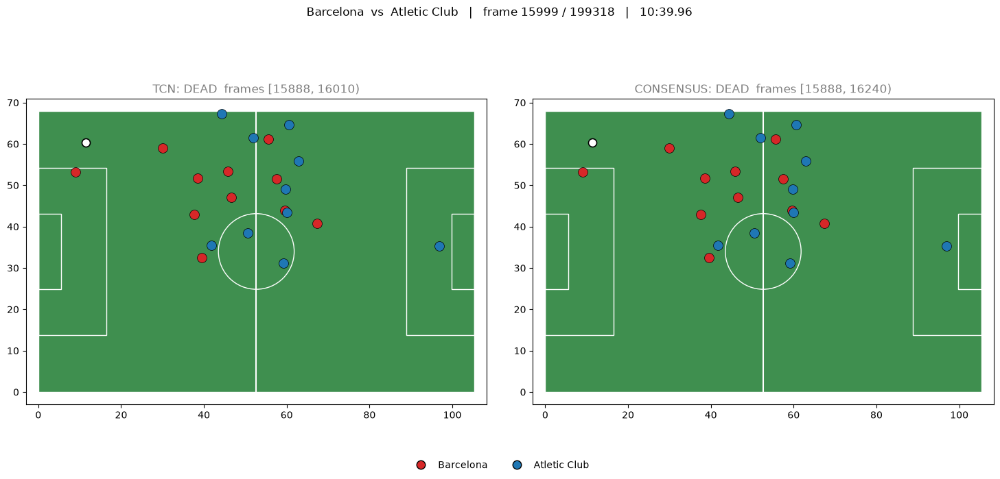

In [9]:
from IPython.display import HTML

anim = animate_barca(
    START_FRAME,
    END_FRAME,
    step=STEP,
    interval=INTERVAL,
    figsize=FIGSIZE,
)
HTML(anim.to_jshtml(fps=FPS))
